<div align="center">

<h2><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h2>


<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<h5><strong> Oleh:</strong></h5>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li>
    <strong>WAHDANIA</strong>
    <div style="margin-top:10px;">
      <strong>H061241070</strong>
    </div>
  </li>
</ul>

<p><strong>DEPARTEMEN GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong></strong></p>
<p><strong></strong></p>
<p><strong>2026</strong></p>

</div>

# **Recipe Geofisika: Pengolahan Data Geolistrik Vertical Electrical Sounding (VES) Konfigurasi Schlumberger**

**Recipe ID:** R-GEO-001 (recipe mandiri)  
**Bidang:** Geofisika dekat permukaan — metode resistivitas listrik  
**Bahasa:** Python  
**Alur:** Problem → Minimal Theory → Input/Data Provenance → QA/QC → Code → Result → Optional Check

> **Penting:** Notebook ini berisi *data demo sintetis* agar alur dapat langsung dijalankan. Data tersebut bukan hasil pengukuran lapangan dan tidak boleh dilaporkan sebagai observasi nyata. Untuk penelitian/tugas dengan data nyata, ganti data demo dengan CSV pengukuran Anda.

## **1. Problem**

Mengolah data Vertical Electrical Sounding (VES) konfigurasi Schlumberger dari pengukuran arus dan beda potensial menjadi resistivitas semu, memeriksa kualitas data, memvisualisasikan kurva VES, dan menyimpan hasil ke CSV.

**Pertanyaan analisis**
1. Bagaimana perubahan resistivitas semu terhadap jarak elektroda arus AB/2?
2. Adakah titik data yang tidak valid atau perlu diperiksa kembali?
3. Apa batas interpretasi kurva resistivitas semu tanpa proses inversi dan informasi geologi pendukung?

**Input**
- `AB_2_m`: setengah jarak elektroda arus AB, meter.
- `MN_2_m`: setengah jarak elektroda potensial MN, meter.
- `I_mA`: arus injeksi, milliampere.
- `V_mV`: beda potensial terukur, millivolt.

**Output**
- tabel bersih dengan faktor geometri dan resistivitas semu (ohm-meter);
- grafik kurva VES skala log-log;
- file `hasil_pengolahan_ves.csv`;
- ringkasan QA/QC.

## **2. Minimal theory**

Untuk konfigurasi Schlumberger dengan $AB/2 = (a) dan MN/2 = (b)4, faktor geometri ideal:

$$
K = \pi \frac{a^2-b^2}{2b}$$

Resistivitas semu:

$$
\rho_a = K\frac{\Delta V}{I}
$$

Karena rasio V/I harus tak berdimensi terhadap satuan yang konsisten, konversi $mV/mA = V/A$ secara numerik bernilai sama. Maka` V_mV / I_mA `langsung dapat digunakan.

**Asumsi:** susunan elektroda Schlumberger simetris, `AB_2_m > MN_2_m > 0` , dan pengukuran arus/tegangan memakai nilai positif. Rumus ini menghitung resistivitas semu; bukan resistivitas lapisan sebenarnya dan bukan hasil inversi.

## 3. Setup dan provenance
Data demo dibuat di notebook sehingga tidak memerlukan internet. Catat sumber, tanggal, lokasi, konfigurasi alat, satuan, dan metode pengukuran ketika menggunakan data nyata.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)

OUTPUT_DIR = Path("results_ves")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Folder output:", OUTPUT_DIR.resolve())

Folder output: C:\Users\THINKPAD T490\Downloads\results_ves


## **4. Input data**

Jalankan sel berikut untuk membuat data demo sintetis. Untuk memakai data nyata, simpan data sebagai CSV dengan nama kolom yang sama, lalu ganti bagian input menggunakan `pd.read_csv("nama_file.csv")`.

Contoh format CSV:

| AB_2_m | MN_2_m | I_mA | V_mV |
|---:|---:|---:|---:|
| 1.0 | 0.3 | 20 | 8.4 |
| 1.5 | 0.3 | 20 | 12.1 |

Nilai pada tabel di atas hanya ilustrasi format, bukan data pengukuran.

In [2]:
# DATA DEMO SINTETIS — ganti dengan pd.read_csv("data_ves.csv") untuk data nyata.
data = pd.DataFrame({
    "AB_2_m": [1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0, 10.0, 15.0, 20.0, 30.0, 40.0],
    "MN_2_m": [0.3, 0.3, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 1.0, 1.0, 2.0, 2.0],
    "I_mA":   [20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20],
    "V_mV":   [8.4, 12.1, 15.0, 20.5, 24.2, 31.0, 34.0, 36.0, 43.0, 47.0, 55.0, 58.0],
})
data.head()

,AB_2_m,MN_2_m,I_mA,V_mV
0,1.0,0.3,20,8.4
1,1.5,0.3,20,12.1
2,2.0,0.3,20,15.0
3,3.0,0.3,20,20.5
4,4.0,0.3,20,24.2


## 5. QA/QC — pemeriksaan awal

Pemeriksaan ini tidak menghapus atau mengubah data sumber. Kita menandai nilai hilang, duplikasi, nilai nonpositif, dan geometri elektroda yang tidak memenuhi syarat. Perbaiki berdasarkan catatan lapangan/instrumen; jangan mengarang nilai pengganti.

In [3]:
required = ["AB_2_m", "MN_2_m", "I_mA", "V_mV"]
missing_columns = sorted(set(required) - set(data.columns))
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_columns}")

df = data[required].copy()
for col in required:
    df[col] = pd.to_numeric(df[col], errors="coerce")

qc = pd.DataFrame(index=df.index)
qc["missing_or_non_numeric"] = df[required].isna().any(axis=1)
qc["duplicate_row"] = df.duplicated(keep=False)
qc["nonpositive_measurement"] = (df[["AB_2_m", "MN_2_m", "I_mA", "V_mV"]] <= 0).any(axis=1)
qc["invalid_electrode_geometry"] = (df["AB_2_m"] <= df["MN_2_m"])
qc["flag_any"] = qc.any(axis=1)

print("Jumlah baris:", len(df))
print("Baris dengan flag QA/QC:", int(qc["flag_any"].sum()))
display(pd.concat([df, qc], axis=1))

Jumlah baris: 12
Baris dengan flag QA/QC: 0


,AB_2_m,MN_2_m,I_mA,V_mV,missing_or_non_numeric,duplicate_row,nonpositive_measurement,invalid_electrode_geometry,flag_any
0,1.0,0.3,20,8.4,False,False,False,False,False
1,1.5,0.3,20,12.1,False,False,False,False,False
2,2.0,0.3,20,15.0,False,False,False,False,False
3,3.0,0.3,20,20.5,False,False,False,False,False
4,4.0,0.3,20,24.2,False,False,False,False,False
5,6.0,0.5,20,31.0,False,False,False,False,False
6,8.0,0.5,20,34.0,False,False,False,False,False
7,10.0,0.5,20,36.0,False,False,False,False,False
8,15.0,1.0,20,43.0,False,False,False,False,False
9,20.0,1.0,20,47.0,False,False,False,False,False


## 6. Hitung faktor geometri dan resistivitas semu

Baris yang gagal pemeriksaan tidak dihitung sebagai hasil valid. Jika data Anda memakai konvensi jarak atau satuan berbeda, sesuaikan rumus hanya setelah memastikan definisi variabel pada catatan pengukuran.

In [4]:
df["K_ohm_factor_m"] = np.nan
df["rho_a_ohm_m"] = np.nan

valid = ~qc["flag_any"]
a = df.loc[valid, "AB_2_m"]
b = df.loc[valid, "MN_2_m"]
K = np.pi * (a**2 - b**2) / (2 * b)
rho_a = K * (df.loc[valid, "V_mV"] / df.loc[valid, "I_mA"])

df.loc[valid, "K_ohm_factor_m"] = K
df.loc[valid, "rho_a_ohm_m"] = rho_a

display(df)

,AB_2_m,MN_2_m,I_mA,V_mV,K_ohm_factor_m,rho_a_ohm_m
0,1.0,0.3,20,8.4,4.7647,2.0012
1,1.5,0.3,20,12.1,11.3097,6.8424
2,2.0,0.3,20,15.0,20.4727,15.3545
3,3.0,0.3,20,20.5,46.6527,47.8190
4,4.0,0.3,20,24.2,83.3046,100.7985
5,6.0,0.5,20,31.0,112.3119,174.0835
6,8.0,0.5,20,34.0,200.2765,340.4701
7,10.0,0.5,20,36.0,313.3739,564.0730
8,15.0,1.0,20,43.0,351.8584,756.4955
9,20.0,1.0,20,47.0,626.7477,1472.8572


## 7. Visualisasi kurva VES

Sumbu-x adalah AB/2 (m) dan sumbu-y adalah resistivitas semu (ohm·m). Skala logaritmik lazim dipakai karena rentang jarak dan resistivitas dapat lebar. Kurva ini membantu eksplorasi; bentuk kurva saja tidak cukup untuk menyimpulkan litologi atau ketebalan lapisan secara unik.

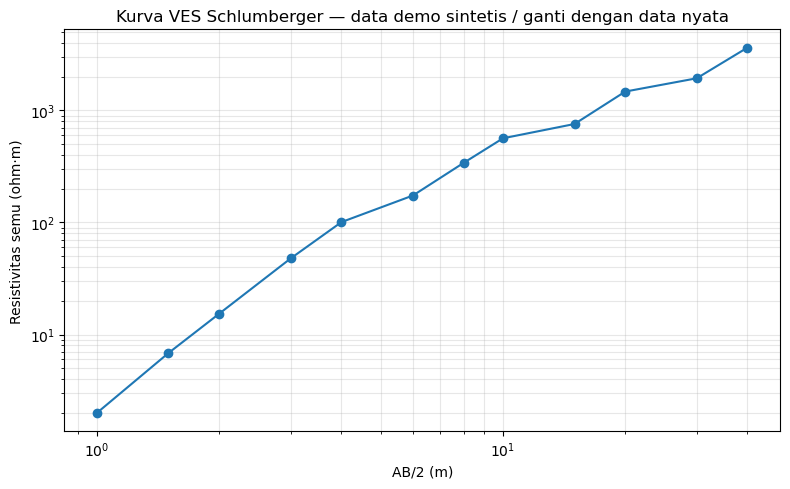

In [5]:
plot_df = df.loc[valid].sort_values("AB_2_m")
if plot_df.empty:
    raise ValueError("Tidak ada baris valid untuk diplot. Periksa data dan flag QA/QC.")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(plot_df["AB_2_m"], plot_df["rho_a_ohm_m"], marker="o")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("AB/2 (m)")
ax.set_ylabel("Resistivitas semu (ohm·m)")
ax.set_title("Kurva VES Schlumberger — data demo sintetis / ganti dengan data nyata")
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
plt.show()

## 8. Ringkasan numerik dan ekspor hasil

Ringkasan berikut hanya menjelaskan nilai hasil hitung dari baris yang lolos QA/QC. Jika data yang digunakan masih sintetis, semua angka ringkasan juga sintetis.

In [6]:
summary = {
    "jumlah_baris_input": int(len(df)),
    "jumlah_baris_valid": int(valid.sum()),
    "jumlah_baris_flag": int((~valid).sum()),
    "rho_a_min_ohm_m": float(df.loc[valid, "rho_a_ohm_m"].min()) if valid.any() else None,
    "rho_a_median_ohm_m": float(df.loc[valid, "rho_a_ohm_m"].median()) if valid.any() else None,
    "rho_a_max_ohm_m": float(df.loc[valid, "rho_a_ohm_m"].max()) if valid.any() else None,
}
pd.Series(summary, name="nilai").to_frame()

,nilai
jumlah_baris_input,12.0000
jumlah_baris_valid,12.0000
jumlah_baris_flag,0.0000
rho_a_min_ohm_m,2.0012
rho_a_median_ohm_m,257.2768
rho_a_max_ohm_m,3635.1369


In [7]:
output = df.copy()
output = pd.concat([output, qc.add_prefix("qc_")], axis=1)
csv_path = OUTPUT_DIR / "hasil_pengolahan_ves.csv"
output.to_csv(csv_path, index=False)
print("CSV tersimpan:", csv_path.resolve())

CSV tersimpan: C:\Users\THINKPAD T490\Downloads\results_ves\hasil_pengolahan_ves.csv


## 9. Optional check / verification

Pemeriksaan sederhana ini memastikan faktor geometri positif pada baris valid, resistivitas semu positif, dan nilai hasil hitung tidak mengandung nilai tak hingga. Ini adalah **verification** terhadap aturan hitung dan input, bukan validasi geologi atau pembuktian bahwa data demo merepresentasikan kondisi lapangan.

In [8]:
if valid.any():
    assert (df.loc[valid, "K_ohm_factor_m"] > 0).all(), "K harus positif untuk geometri valid."
    assert (df.loc[valid, "rho_a_ohm_m"] > 0).all(), "Resistivitas semu harus positif."
    assert np.isfinite(df.loc[valid, "rho_a_ohm_m"]).all(), "Ditemukan hasil non-finite."
    print("Verification dasar: LULUS")
else:
    print("Verification tidak dapat dilakukan: tidak ada data valid.")

print("Catatan: hasil verification tidak menggantikan pemeriksaan catatan lapangan, instrumen, dan interpretasi geofisika.")

Verification dasar: LULUS
Catatan: hasil verification tidak menggantikan pemeriksaan catatan lapangan, instrumen, dan interpretasi geofisika.


## 10. Interpretasi dan batasan

Gunakan hasil untuk menjawab pertanyaan analisis secara terbatas:

- Jelaskan tren kurva yang benar-benar terlihat, bukan langsung menetapkan litologi.
- Periksa titik yang menyimpang terhadap catatan pengukuran sebelum menghapusnya.
- Resistivitas semu merupakan respons gabungan bawah permukaan; interpretasi lapisan umumnya membutuhkan inversi 1D/2D, model awal, asumsi, dan evaluasi ketidakpastian.
- Jangan menyebut data demo sebagai data lapangan. Saat mengganti data, dokumentasikan lokasi, tanggal, alat, konfigurasi, satuan, dan asal file.

## 11. Run record

Isi catatan berikut setelah menjalankan notebook dengan data Anda:

- **Sumber data / nama file:** ...
- **Lokasi dan tanggal pengukuran:** ...
- **Konfigurasi dan satuan:** Schlumberger; AB/2 dan MN/2 dalam meter; I dalam mA; V dalam mV.
- **Environment Python dan versi paket:** ...
- **Jumlah baris input / valid / flagged:** ...
- **Output yang dihasilkan:** `results_ves/hasil_pengolahan_ves.csv`
- **Masalah yang ditemukan dan keputusan QC:** ...
- **Status eksekusi:** isi berdasarkan eksekusi aktual, jangan mengklaim berhasil sebelum sel dijalankan.

## 12. Hubungan dengan pola recipe pada buku

Notebook ini mengikuti pola yang ditekankan dalam *AI Cookbook untuk Earth Sciences*: **Problem → Minimal Theory → Prompt/Specification → Code → Result → Optional Check**, dengan perhatian pada provenance, unit, QA/QC, output yang dapat digunakan ulang, dan batas interpretasi. Recipe ini dibuat khusus sebagai latihan pengolahan VES, bukan salinan recipe resmi dari buku.